GO and KEGG for validated database (miRTarBase + TarBase)

In [5]:
%load_ext rpy2.ipython

In [6]:
%%R
# Cài đặt BiocManager nếu chưa có
if (!require("BiocManager", quietly = TRUE))
    install.packages("BiocManager", repos="http://cran.us.r-project.org")

# Dùng BiocManager để cài đặt multiMiR
BiocManager::install("multiMiR", ask=FALSE)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)
trying URL 'http://cran.us.r-project.org/src/contrib/BiocManager_1.30.27.tar.gz'
Content type 'application/x-gzip' length 752490 bytes (734 KB)
downloaded 734 KB


The downloaded source packages are in
	‘/tmp/Rtmpgzxwou/downloaded_packages’
'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.rstudio.com
Bioconductor version 3.23 (BiocManager 1.30.27), R 4.6.0 (2026-04-24)
Installing package(s) 'BiocVersion', 'multiMiR'
also installing the dependencies ‘XVector’, ‘Seqinfo’, ‘png’, ‘Biostrings’, ‘bitops’, ‘Biobase’, ‘IRanges’, ‘RSQLite’, ‘S4Vectors’, ‘KEGGREST’, ‘XML’, ‘RCurl’, ‘BiocGenerics’, ‘AnnotationDbi’

trying URL 'https://bioconductor.org/packages/3.23/bioc/src/contrib/XVector_0.52.0.tar.gz'
trying URL 'https://bioconductor.org/packages/3.23/bioc/src/contrib/Seqinfo_1.2.0.t

In [7]:
import rpy2.robjects as ro
from rpy2.robjects.packages import importr
from rpy2.robjects.vectors import StrVector
from rpy2.robjects import pandas2ri, default_converter
from rpy2.robjects.conversion import localconverter

multiMiR = importr("multiMiR")
mirnas = StrVector(["hsa-miR-337-3p", "hsa-miR-200a-3p"])
res = multiMiR.get_multimir(mirna=mirnas, table="validated", summary=False)
with localconverter(default_converter + pandas2ri.converter):
    df = ro.conversion.rpy2py(res.slots["data"])
genes_mirtarbase = set(df[df["database"]=="mirtarbase"]["target_symbol"].unique())
genes_tarbase    = set(df[df["database"]=="tarbase"]["target_symbol"].unique())
genes_union = list(genes_mirtarbase.union(genes_tarbase))
print("mirtarbase genes:", len(genes_mirtarbase), "| tarbase genes:", len(genes_tarbase), "| union:", len(genes_union))

Searching mirecords ...
Searching mirtarbase ...
Searching tarbase ...
mirtarbase genes: 243 | tarbase genes: 1844 | union: 1997


Biological process

In [10]:
%%R
BiocManager::install(c("clusterProfiler", "org.Hs.eg.db"), ask=FALSE)

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.rstudio.com
Bioconductor version 3.23 (BiocManager 1.30.27), R 4.6.0 (2026-04-24)
Installing package(s) 'clusterProfiler', 'org.Hs.eg.db'
also installing the dependencies ‘fontBitstreamVera’, ‘fontLiberation’, ‘fontquiver’, ‘gridGraphics’, ‘gdtools’, ‘lazyeval’, ‘tweenr’, ‘polyclip’, ‘ggplotify’, ‘patchwork’, ‘ape’, ‘ggiraph’, ‘tidytree’, ‘treeio’, ‘ggforce’, ‘RcppEigen’, ‘aplot’, ‘DOSE’, ‘ggfun’, ‘ggnewscale’, ‘ggrepel’, ‘ggtangle’, ‘ggtree’, ‘reshape2’, ‘scatterpie’, ‘tidydr’, ‘aisdk’, ‘enrichit’, ‘enrichplot’, ‘GO.db’, ‘GOSemSim’, ‘gson’, ‘igraph’, ‘plyr’, ‘qvalue’, ‘yulab.utils’

trying URL 'https://cran.rstudio.com/src/contrib/fontBitstreamVera_0.1.1.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/fontLiberation_0.1.0.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/fontquiver_0.2.1.tar.

In [12]:
!mkdir outputs_2miRNA_brca

                                                    Description GeneRatio
GO:0051052                  regulation of DNA metabolic process   99/1880
GO:0008380                                         RNA splicing   99/1880
GO:0042176              regulation of protein catabolic process   84/1880
GO:0006913                          nucleocytoplasmic transport   67/1880
GO:0051169                                    nuclear transport   67/1880
GO:0040029             epigenetic regulation of gene expression   74/1880
GO:0043484                           regulation of RNA splicing   49/1880
GO:0044089 positive regulation of cellular component biogenesis   92/1880
GO:0010638        positive regulation of organelle organization   89/1880
GO:1901888                 regulation of cell junction assembly   59/1880
GO:0050803          regulation of synapse structure or activity   65/1880
GO:0033044                regulation of chromosome organization   55/1880
               p.adjust
GO:0051052 8.6

'select()' returned 1:1 mapping between keys and columns
In addition: Warning message:
In bitr(genes_union, fromType = "SYMBOL", toType = "ENTREZID", OrgDb = org.Hs.eg.db) :
  0.6% of input gene IDs are fail to map...


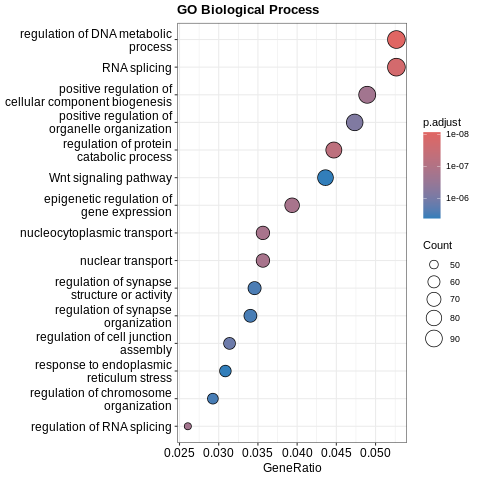

In [13]:
%%R -i genes_union
suppressMessages({library(clusterProfiler); library(org.Hs.eg.db); library(ggplot2)})
gene_ids <- bitr(genes_union, fromType="SYMBOL", toType="ENTREZID", OrgDb=org.Hs.eg.db)
ego_bp <- enrichGO(gene=gene_ids$ENTREZID, OrgDb=org.Hs.eg.db, keyType="ENTREZID",
                   ont="BP", pAdjustMethod="BH", pvalueCutoff=0.05, qvalueCutoff=0.2)
p <- dotplot(ego_bp, showCategory=15, title="GO Biological Process") + theme(plot.title=element_text(face="bold"))
print(p)
ggsave("outputs_2miRNA_brca/GO_BP_dotplot.png", plot=p, width=11, height=9, dpi=200, create.dir = TRUE)
print(head(as.data.frame(ego_bp)[,c("Description","GeneRatio","p.adjust")], 12))

Cellular Component

                                     Description GeneRatio     p.adjust
GO:0005635                      nuclear envelope   88/1931 1.410861e-07
GO:0010494            cytoplasmic stress granule   32/1931 1.410861e-07
GO:0005667       transcription regulator complex   89/1931 2.588942e-07
GO:0016607                         nuclear speck   79/1931 3.047919e-07
GO:0140168     nuclear ribonucleoprotein granule   89/1931 3.274305e-07
GO:0030055               cell-substrate junction   78/1931 7.321551e-07
GO:0098687                    chromosomal region   78/1931 7.321551e-07
GO:0036464 cytoplasmic ribonucleoprotein granule   54/1931 7.321551e-07
GO:0005925                        focal adhesion   76/1931 7.321551e-07
GO:0031965                      nuclear membrane   57/1931 1.408339e-06
GO:0005681                  spliceosomal complex   47/1931 2.368520e-06
GO:0031252                     cell leading edge   79/1931 2.368520e-06


'select()' returned 1:1 mapping between keys and columns
In addition: Warning message:
In bitr(genes_union, fromType = "SYMBOL", toType = "ENTREZID", OrgDb = org.Hs.eg.db) :
  0.6% of input gene IDs are fail to map...


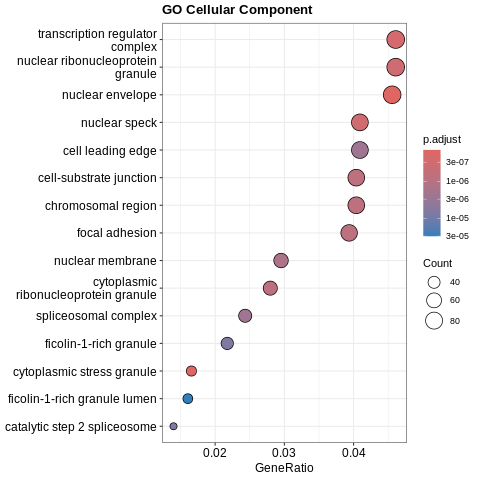

In [14]:
%%R -i genes_union
gene_ids <- bitr(genes_union, fromType="SYMBOL", toType="ENTREZID", OrgDb=org.Hs.eg.db)
ego_cc <- enrichGO(gene=gene_ids$ENTREZID, OrgDb=org.Hs.eg.db, keyType="ENTREZID",
                   ont="CC", pAdjustMethod="BH", pvalueCutoff=0.05, qvalueCutoff=0.2)
p <- dotplot(ego_cc, showCategory=15, title="GO Cellular Component") + theme(plot.title=element_text(face="bold"))
print(p)
ggsave("outputs_2miRNA_brca/GO_CC_dotplot.png", plot=p, width=11, height=9, dpi=200)
print(head(as.data.frame(ego_cc)[,c("Description","GeneRatio","p.adjust")], 12))

Molecular function

                                                                   Description
GO:0140297                            DNA-binding transcription factor binding
GO:0004674                            protein serine/threonine kinase activity
GO:0061629 RNA polymerase II-specific DNA-binding transcription factor binding
GO:0106310                                      protein serine kinase activity
GO:0045296                                                    cadherin binding
GO:0140693                              molecular condensate scaffold activity
GO:0001221                                   transcription coregulator binding
GO:0003713                                  transcription coactivator activity
GO:0016887                                             ATP hydrolysis activity
GO:0004842                              ubiquitin-protein transferase activity
GO:0120545                        nucleic acid conformation isomerase activity
GO:0019787                         ubiquitin-like pr

'select()' returned 1:1 mapping between keys and columns
In addition: Warning message:
In bitr(genes_union, fromType = "SYMBOL", toType = "ENTREZID", OrgDb = org.Hs.eg.db) :
  0.6% of input gene IDs are fail to map...


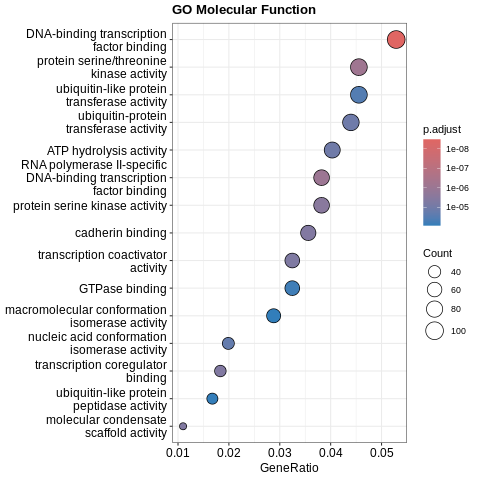

In [15]:
%%R -i genes_union
gene_ids <- bitr(genes_union, fromType="SYMBOL", toType="ENTREZID", OrgDb=org.Hs.eg.db)
ego_mf <- enrichGO(gene=gene_ids$ENTREZID, OrgDb=org.Hs.eg.db, keyType="ENTREZID",
                   ont="MF", pAdjustMethod="BH", pvalueCutoff=0.05, qvalueCutoff=0.2)
p <- dotplot(ego_mf, showCategory=15, title="GO Molecular Function") + theme(plot.title=element_text(face="bold"))
print(p)
ggsave("outputs_2miRNA_brca/GO_MF_dotplot.png", plot=p, width=11, height=9, dpi=200)
print(head(as.data.frame(ego_mf)[,c("Description","GeneRatio","p.adjust")], 12))

KEGG

                                    Description GeneRatio     p.adjust
hsa05205                Proteoglycans in cancer    56/979 1.366131e-09
hsa04218                    Cellular senescence    47/979 1.367002e-09
hsa05210                      Colorectal cancer    30/979 1.360317e-07
hsa04520                      Adherens junction    30/979 6.179410e-07
hsa04350             TGF-beta signaling pathway    33/979 6.874706e-07
hsa04110                             Cell cycle    41/979 8.251442e-07
hsa04530                         Tight junction    43/979 8.251442e-07
hsa05225               Hepatocellular carcinoma    43/979 8.251442e-07
hsa05100 Bacterial invasion of epithelial cells    26/979 1.292238e-06
hsa05215                        Prostate cancer    31/979 1.856085e-06
hsa01522                   Endocrine resistance    29/979 4.351673e-06
hsa04390                Hippo signaling pathway    38/979 1.247899e-05
hsa04919      Thyroid hormone signaling pathway    32/979 1.385210e-05
hsa045

'select()' returned 1:1 mapping between keys and columns
Reading KEGG annotation online: "https://rest.kegg.jp/link/hsa/pathway"...
Reading KEGG annotation online: "https://rest.kegg.jp/list/pathway/hsa"...
kegg_category.rda is not found, download it online...
In addition: Warning message:
In bitr(genes_union, fromType = "SYMBOL", toType = "ENTREZID", OrgDb = org.Hs.eg.db) :
  0.6% of input gene IDs are fail to map...


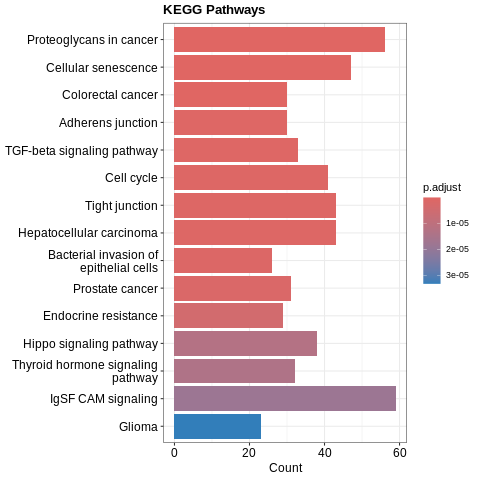

In [16]:
%%R -i genes_union
gene_ids <- bitr(genes_union, fromType="SYMBOL", toType="ENTREZID", OrgDb=org.Hs.eg.db)
ekegg <- enrichKEGG(gene=gene_ids$ENTREZID, organism="hsa", pvalueCutoff=0.05)
p <- barplot(ekegg, showCategory=15, title="KEGG Pathways") + theme(plot.title=element_text(face="bold"))
print(p)
ggsave("outputs_2miRNA_brca/KEGG_barplot.png", plot=p, width=11, height=9, dpi=200)
print(head(as.data.frame(ekegg)[,c("Description","GeneRatio","p.adjust")], 15))